In [25]:
import pandas as pd
import numpy as np
import glob
import json
import os

# =========================================================
# 1. PATH TO FILES
# =========================================================

DATA_PATH = "/home/ilbekas/Workload Scheduler/scheduler/results/*.json"

files = glob.glob(DATA_PATH)

print(f"Files found: {len(files)}")

# =========================================================
# 2. EXP → CONCURRENCY MAP
# =========================================================

EXP_MAP = {
    "EXP1": "LOW",
    "EXP2": "MEDIUM",
    "EXP3": "HIGH"
}

# =========================================================
# 3. LOAD ALL FILES
# =========================================================

all_data = []

for f in files:
    try:
        with open(f, "r") as file:
            data = json.load(file)

        # detect experiment type from filename
        base = os.path.basename(f)

        exp_key = None
        for k in EXP_MAP.keys():
            if k in base:
                exp_key = k
                break

        if exp_key is None:
            print(f"Skipping unknown file: {base}")
            continue

        concurrency = EXP_MAP[exp_key]

        for row in data:
            row["source_file"] = base
            row["concurrency"] = concurrency
            all_data.append(row)

    except Exception as e:
        print(f"Error reading {f}: {e}")

# =========================================================
# 4. BUILD DATAFRAME
# =========================================================

df = pd.DataFrame(all_data)

print("\n========== DATA LOADED ==========")
print(df.shape)

print("\nConcurrency distribution:")
print(df["concurrency"].value_counts())

Files found: 35

========== DATA LOADED ==========
(689, 12)

Concurrency distribution:
concurrency
MEDIUM    237
LOW       237
HIGH      215
Name: count, dtype: int64


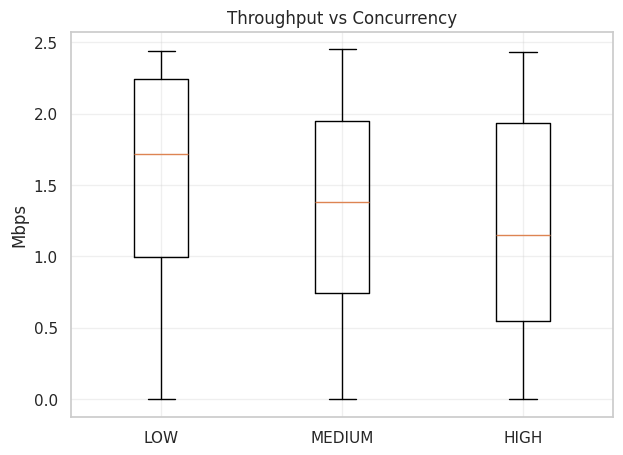

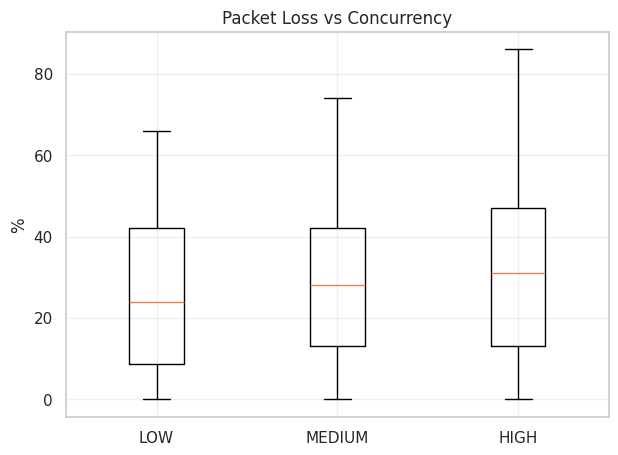

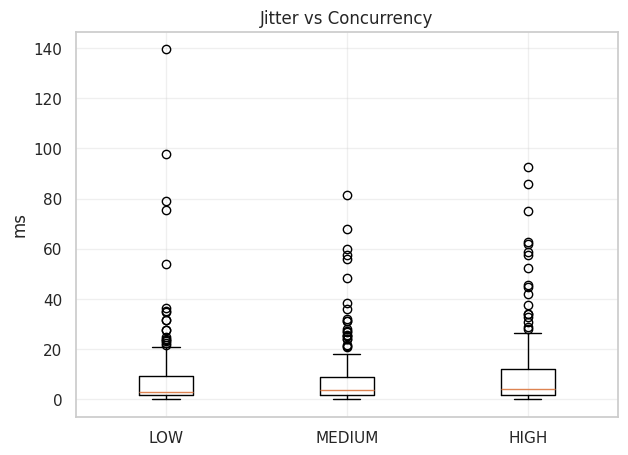

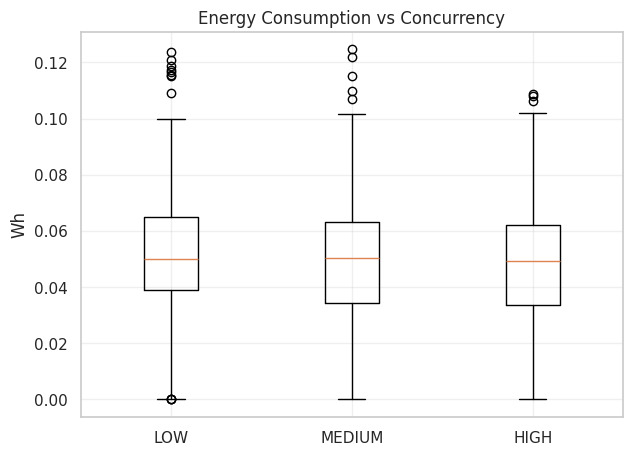

In [30]:
import matplotlib.pyplot as plt

def plot_box(metric, ylabel, title):
    # Only use labels that actually exist in the data
    order = ["LOW", "MEDIUM", "HIGH"]
    order = [x for x in order if x in df["concurrency"].unique()]

    data = [
        df[df["concurrency"] == c][metric].dropna()
        for c in order
    ]

    # Check if we actually have data before plotting
    if not any(len(d) > 0 for d in data):
        print(f"No data found for metric: {metric}")
        return

    plt.figure(figsize=(7,5))
    # Changed to tick_labels to match newer Matplotlib versions
    plt.boxplot(data, tick_labels=order) 
    plt.title(title)
    plt.ylabel(ylabel)
    plt.grid(alpha=0.3)
    plt.show()

# --- THE MISSING STEP: CALLING THE FUNCTION ---
plot_box("throughput_mbps", "Mbps", "Throughput vs Concurrency")
plot_box("packet_loss_percent", "%", "Packet Loss vs Concurrency")
plot_box("jitter_ms", "ms", "Jitter vs Concurrency")
plot_box(
    "total_energy_Wh",
    "Wh",
    "Energy Consumption vs Concurrency"
)

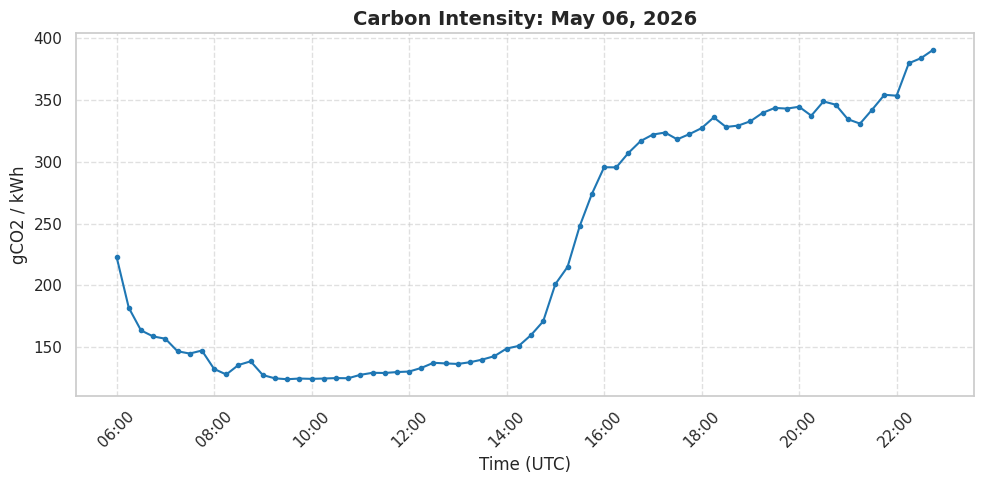

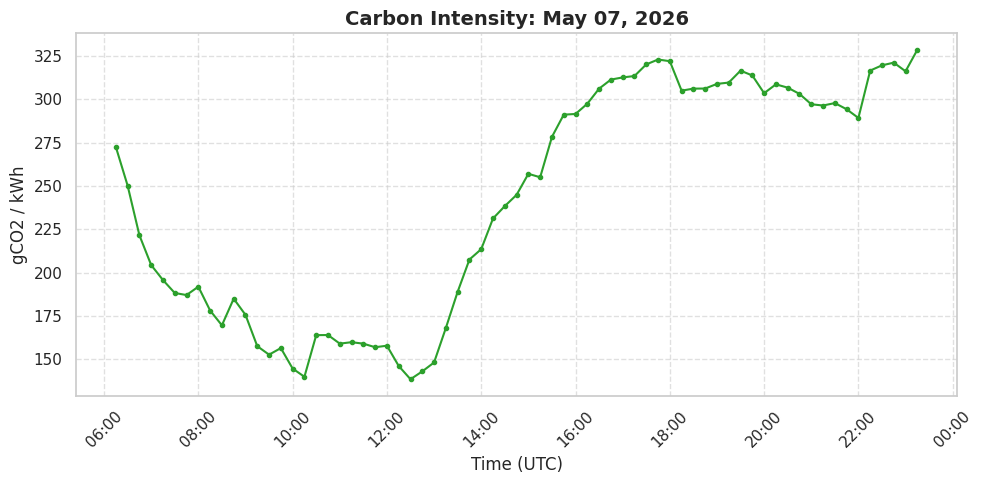

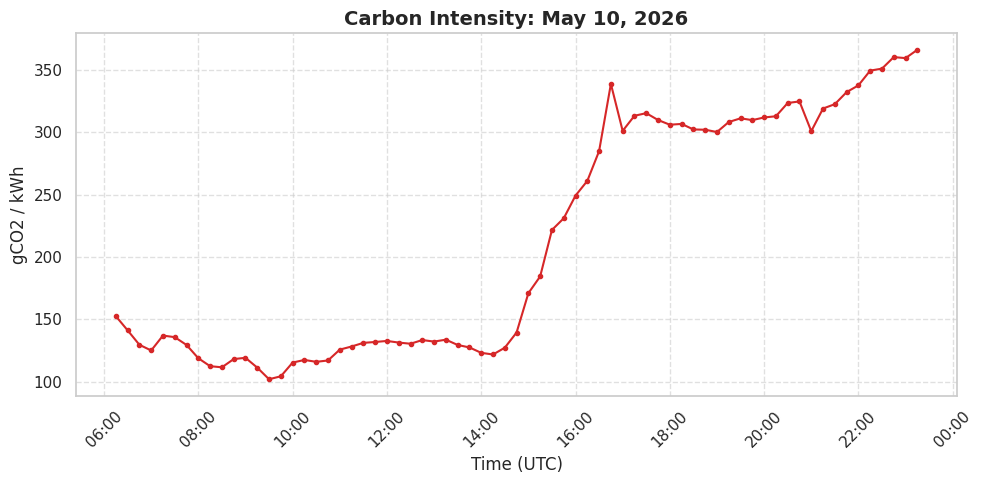

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1. DATA LOADING
# =========================================================

day1_data = [ { "footprint_type": "carbon", "scope": "life-cycle", "zone": "GR", "unit": "gCO2/kWh", "coverage": "global", "series": [ { "valid": True, "zone_status": "complete", "values": [ ["2026-05-06T06:00:00Z", 223.11], ["2026-05-06T06:15:00Z", 181.92], ["2026-05-06T06:30:00Z", 163.61], ["2026-05-06T06:45:00Z", 158.67], ["2026-05-06T07:00:00Z", 156.83], ["2026-05-06T07:15:00Z", 146.67], ["2026-05-06T07:30:00Z", 144.82], ["2026-05-06T07:45:00Z", 147.26], ["2026-05-06T08:00:00Z", 132.36], ["2026-05-06T08:15:00Z", 127.86], ["2026-05-06T08:30:00Z", 135.56], ["2026-05-06T08:45:00Z", 138.52], ["2026-05-06T09:00:00Z", 127.38], ["2026-05-06T09:15:00Z", 124.73], ["2026-05-06T09:30:00Z", 124.02], ["2026-05-06T09:45:00Z", 124.58], ["2026-05-06T10:00:00Z", 124.32], ["2026-05-06T10:15:00Z", 124.58], ["2026-05-06T10:30:00Z", 124.95], ["2026-05-06T10:45:00Z", 124.82], ["2026-05-06T11:00:00Z", 127.59], ["2026-05-06T11:15:00Z", 129.23], ["2026-05-06T11:30:00Z", 129.09], ["2026-05-06T11:45:00Z", 129.82], ["2026-05-06T12:00:00Z", 130.25], ["2026-05-06T12:15:00Z", 133.17], ["2026-05-06T12:30:00Z", 137.34], ["2026-05-06T12:45:00Z", 136.82], ["2026-05-06T13:00:00Z", 136.4], ["2026-05-06T13:15:00Z", 137.79], ["2026-05-06T13:30:00Z", 139.92], ["2026-05-06T13:45:00Z", 142.72], ["2026-05-06T14:00:00Z", 148.86], ["2026-05-06T14:15:00Z", 151.01], ["2026-05-06T14:30:00Z", 159.74], ["2026-05-06T14:45:00Z", 170.87], ["2026-05-06T15:00:00Z", 201], ["2026-05-06T15:15:00Z", 214.93], ["2026-05-06T15:30:00Z", 248.02], ["2026-05-06T15:45:00Z", 274.1], ["2026-05-06T16:00:00Z", 295.66], ["2026-05-06T16:15:00Z", 295.56], ["2026-05-06T16:30:00Z", 307.31], ["2026-05-06T16:45:00Z", 316.89], ["2026-05-06T17:00:00Z", 322.13], ["2026-05-06T17:15:00Z", 323.76], ["2026-05-06T17:30:00Z", 318.26], ["2026-05-06T17:45:00Z", 322.49], ["2026-05-06T18:00:00Z", 327.33], ["2026-05-06T18:15:00Z", 336.02], ["2026-05-06T18:30:00Z", 328.29], ["2026-05-06T18:45:00Z", 329.37], ["2026-05-06T19:00:00Z", 332.88], ["2026-05-06T19:15:00Z", 339.65], ["2026-05-06T19:30:00Z", 343.69], ["2026-05-06T19:45:00Z", 343.16], ["2026-05-06T20:00:00Z", 344.63], ["2026-05-06T20:15:00Z", 337.41], ["2026-05-06T20:30:00Z", 348.95], ["2026-05-06T20:45:00Z", 346.31], ["2026-05-06T21:15:00Z", 330.97], ["2026-05-06T21:30:00Z", 342.38], ["2026-05-06T21:45:00Z", 354.33], ["2026-05-06T22:00:00Z", 353.59], ["2026-05-06T22:15:00Z", 379.87], ["2026-05-06T22:30:00Z", 383.97], ["2026-05-06T22:45:00Z", 390.75] ] }, { "valid": True, "zone_status": "preview", "values": [ ["2026-05-06T21:00:00Z", 334.55] ] } ] } ]

day2_data = [ { "footprint_type": "carbon", "scope": "life-cycle", "zone": "GR", "unit": "gCO2/kWh", "coverage": "global", "series": [ { "valid": True, "zone_status": "complete", "values": [ ["2026-05-07T06:15:00Z", 272.49], ["2026-05-07T06:30:00Z", 250.18], ["2026-05-07T06:45:00Z", 221.58], ["2026-05-07T07:00:00Z", 204.38], ["2026-05-07T07:15:00Z", 195.75], ["2026-05-07T07:30:00Z", 188.3], ["2026-05-07T07:45:00Z", 187.11], ["2026-05-07T08:00:00Z", 191.94], ["2026-05-07T08:15:00Z", 178.19], ["2026-05-07T08:30:00Z", 169.68], ["2026-05-07T08:45:00Z", 185.01], ["2026-05-07T09:00:00Z", 175.7], ["2026-05-07T09:15:00Z", 157.66], ["2026-05-07T09:30:00Z", 152.77], ["2026-05-07T09:45:00Z", 156.55], ["2026-05-07T10:00:00Z", 144.77], ["2026-05-07T10:15:00Z", 140.03], ["2026-05-07T10:30:00Z", 164.01], ["2026-05-07T10:45:00Z", 164.08], ["2026-05-07T11:00:00Z", 159.13], ["2026-05-07T11:15:00Z", 159.95], ["2026-05-07T11:30:00Z", 159.11], ["2026-05-07T11:45:00Z", 157.05], ["2026-05-07T12:00:00Z", 157.93], ["2026-05-07T12:15:00Z", 146.25], ["2026-05-07T12:30:00Z", 138.61], ["2026-05-07T12:45:00Z", 143.14], ["2026-05-07T13:00:00Z", 148.26], ["2026-05-07T13:15:00Z", 168.15], ["2026-05-07T13:30:00Z", 188.99], ["2026-05-07T13:45:00Z", 207.58], ["2026-05-07T14:00:00Z", 213.55], ["2026-05-07T14:15:00Z", 231.23], ["2026-05-07T14:30:00Z", 238.35], ["2026-05-07T14:45:00Z", 244.84], ["2026-05-07T15:00:00Z", 256.97], ["2026-05-07T15:15:00Z", 254.97], ["2026-05-07T15:30:00Z", 278.25], ["2026-05-07T15:45:00Z", 291.04], ["2026-05-07T16:00:00Z", 291.44], ["2026-05-07T16:15:00Z", 297.34], ["2026-05-07T16:30:00Z", 306.02], ["2026-05-07T16:45:00Z", 311.24], ["2026-05-07T17:00:00Z", 312.5], ["2026-05-07T17:15:00Z", 313.3], ["2026-05-07T17:30:00Z", 319.99], ["2026-05-07T17:45:00Z", 322.81], ["2026-05-07T18:00:00Z", 321.85], ["2026-05-07T18:15:00Z", 304.88], ["2026-05-07T18:30:00Z", 306.04], ["2026-05-07T18:45:00Z", 306.1], ["2026-05-07T19:00:00Z", 308.77], ["2026-05-07T19:15:00Z", 309.53], ["2026-05-07T19:30:00Z", 316.4], ["2026-05-07T19:45:00Z", 313.62], ["2026-05-07T20:00:00Z", 303.41], ["2026-05-07T20:15:00Z", 308.51], ["2026-05-07T20:30:00Z", 306.61], ["2026-05-07T20:45:00Z", 303.01], ["2026-05-07T21:15:00Z", 296.31], ["2026-05-07T21:30:00Z", 297.72], ["2026-05-07T21:45:00Z", 294.17], ["2026-05-07T22:00:00Z", 289.14], ["2026-05-07T22:15:00Z", 316.45], ["2026-05-07T22:30:00Z", 319.46], ["2026-05-07T22:45:00Z", 321.01], ["2026-05-07T23:00:00Z", 316.04], ["2026-05-07T23:15:00Z", 328.41] ] }, { "valid": True, "zone_status": "preview", "values": [ ["2026-05-07T21:00:00Z", 297.04] ] } ] } ]

day3_data = [ { "footprint_type": "carbon", "scope": "life-cycle", "zone": "GR", "unit": "gCO2/kWh", "coverage": "global", "series": [ { "valid": True, "zone_status": "complete", "values": [ ["2026-05-10T06:15:00Z", 152.62], ["2026-05-10T06:30:00Z", 141.27], ["2026-05-10T06:45:00Z", 129.65], ["2026-05-10T07:00:00Z", 125.08], ["2026-05-10T07:15:00Z", 137.05], ["2026-05-10T07:30:00Z", 135.77], ["2026-05-10T07:45:00Z", 129.5], ["2026-05-10T08:00:00Z", 118.85], ["2026-05-10T08:15:00Z", 112.48], ["2026-05-10T08:30:00Z", 111.58], ["2026-05-10T08:45:00Z", 118.18], ["2026-05-10T09:00:00Z", 119.21], ["2026-05-10T09:15:00Z", 111.32], ["2026-05-10T09:30:00Z", 102.01], ["2026-05-10T09:45:00Z", 104.38], ["2026-05-10T10:00:00Z", 115.38], ["2026-05-10T10:15:00Z", 117.48], ["2026-05-10T10:30:00Z", 115.98], ["2026-05-10T10:45:00Z", 117.06], ["2026-05-10T11:00:00Z", 125.77], ["2026-05-10T11:15:00Z", 128.27], ["2026-05-10T11:30:00Z", 131.2], ["2026-05-10T11:45:00Z", 131.89], ["2026-05-10T12:00:00Z", 132.74], ["2026-05-10T12:15:00Z", 131.42], ["2026-05-10T12:30:00Z", 130.5], ["2026-05-10T12:45:00Z", 133.44], ["2026-05-10T13:00:00Z", 132.23], ["2026-05-10T13:15:00Z", 133.75], ["2026-05-10T13:30:00Z", 129.5], ["2026-05-10T13:45:00Z", 127.53], ["2026-05-10T14:00:00Z", 123.19], ["2026-05-10T14:15:00Z", 121.86], ["2026-05-10T14:30:00Z", 127.3], ["2026-05-10T14:45:00Z", 139.49], ["2026-05-10T15:00:00Z", 171.04], ["2026-05-10T15:15:00Z", 184.49], ["2026-05-10T15:30:00Z", 221.78], ["2026-05-10T15:45:00Z", 231.15], ["2026-05-10T16:00:00Z", 249.33], ["2026-05-10T16:15:00Z", 261.15], ["2026-05-10T16:30:00Z", 285.02], ["2026-05-10T17:00:00Z", 301.29], ["2026-05-10T17:15:00Z", 313.4], ["2026-05-10T17:30:00Z", 315.5], ["2026-05-10T17:45:00Z", 310.01], ["2026-05-10T18:00:00Z", 306.22], ["2026-05-10T18:15:00Z", 306.86], ["2026-05-10T18:30:00Z", 302.43], ["2026-05-10T18:45:00Z", 302.2], ["2026-05-10T19:00:00Z", 300.36], ["2026-05-10T19:15:00Z", 308.38], ["2026-05-10T19:30:00Z", 311.35], ["2026-05-10T19:45:00Z", 309.91], ["2026-05-10T20:00:00Z", 312.05], ["2026-05-10T20:15:00Z", 313.01], ["2026-05-10T20:30:00Z", 323.64], ["2026-05-10T20:45:00Z", 324.92], ["2026-05-10T21:15:00Z", 319.22], ["2026-05-10T21:30:00Z", 322.71], ["2026-05-10T21:45:00Z", 332.39], ["2026-05-10T22:00:00Z", 337.8], ["2026-05-10T22:15:00Z", 349.63], ["2026-05-10T22:30:00Z", 351.22], ["2026-05-10T22:45:00Z", 360.48], ["2026-05-10T23:00:00Z", 359.65], ["2026-05-10T23:15:00Z", 366.33] ] }, { "valid": True, "zone_status": "preview", "values": [ ["2026-05-10T16:45:00Z", 338.97], ["2026-05-10T21:00:00Z", 301.03] ] } ] } ]

# =========================================================
# 2. PROCESSING FUNCTION
# =========================================================

def process_data(raw_json):
    all_points = []
    for series in raw_json[0]["series"]:
        all_points.extend(series["values"])
    
    df = pd.DataFrame(all_points, columns=["time", "intensity"])
    df["time"] = pd.to_datetime(df["time"])
    return df.sort_values("time")

# =========================================================
# 3. PLOTTING
# =========================================================

days_to_plot = [
    (day1_data, "Carbon Intensity: May 06, 2026", "tab:blue"),
    (day2_data, "Carbon Intensity: May 07, 2026", "tab:green"),
    (day3_data, "Carbon Intensity: May 10, 2026", "tab:red")
]

for data, title, color in days_to_plot:
    df_plot = process_data(data)
    
    plt.figure(figsize=(10, 5))
    plt.plot(df_plot["time"], df_plot["intensity"], marker='o', markersize=3, color=color, linewidth=1.5)
    
    # Grid and Labels
    plt.title(title, fontsize=14, fontweight='bold')
    plt.ylabel("gCO2 / kWh", fontsize=12)
    plt.xlabel("Time (UTC)", fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    
    # X-Axis formatting (Show hours)
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    plt.gca().xaxis.set_major_locator(mdates.HourLocator(interval=2))
    plt.xticks(rotation=45)
    
    plt.tight_layout()
    plt.show()